# What an LLM actually sees: next-token prediction and tokenisers for genes, DNA and proteins

**Module 04.3 · my implementation**, Seid Adem

> **Why this matters, in plain language.** A large language model (LLM) such as ChatGPT does one thing: given some
> text, it predicts **the next piece of text**, over and over. But it never sees letters or words. A **tokeniser**
> first chops text into pieces from a fixed vocabulary (**tokens**), and the model only ever sees those pieces as
> numbers. How a gene name or a DNA sequence is chopped up decides what the model can and can't do with it.
> ([Lessons 1–2](../LESSONS.md))

This notebook:

1. **Watches next-token prediction** in a real (small) open LLM, Qwen2.5-0.5B-Instruct.
2. **Measures how six tokenisers split all 20,188 human gene symbols** from UniProt: general-purpose (GPT-2, BERT,
   Qwen2.5), biomedical (BioBERT family, PubMedBERT) and protein (ESM-2).
3. **Feeds them DNA and protein sequences**, with two surprises.
4. **Tests a character-level task** (counting letters in DNA) that LLMs are known to struggle with.

All models are openly licensed (MIT or Apache-2.0) and run on a laptop.

In [1]:
import io
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer

from dsls.ebi_api import uniprot
from dsls.seq import kmers
from dsls.textclf import pick_device

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
SEED = 0
DEVICE = pick_device()
LLM = "Qwen/Qwen2.5-0.5B-Instruct"
tok_llm = AutoTokenizer.from_pretrained(LLM)
llm = AutoModelForCausalLM.from_pretrained(LLM, torch_dtype=torch.float32).to(DEVICE).eval()
print(
    f"{LLM}: {sum(p.numel() for p in llm.parameters()) / 1e6:.0f} M parameters, vocabulary {len(tok_llm):,} tokens"
)

Qwen/Qwen2.5-0.5B-Instruct: 494 M parameters, vocabulary 151,665 tokens


## 1 · The core task: predict the next token

> **In plain language.** Give the model a beginning, and it returns a **probability for every token in its
> vocabulary** (about 150,000 here) being the next one. Generating text is just: pick a token, append it, repeat.
> Everything an assistant "knows" is stored as these learned probabilities.

In [2]:
@torch.no_grad()
def next_token_table(prompt, k=8):
    ids = tok_llm(prompt, return_tensors="pt").to(DEVICE)
    probs = torch.softmax(llm(**ids).logits[0, -1].float(), dim=-1)
    top = probs.topk(k)
    return pd.DataFrame(
        {
            "next token": [repr(tok_llm.decode(i)) for i in top.indices],
            "probability": top.values.cpu().numpy(),
        }
    )


for prompt in (
    "The tumour suppressor gene TP53 encodes a protein that",
    "The UniProt accession of human TP53 is",
):
    print(prompt, "…")
    print(next_token_table(prompt).round(3).to_string(index=False), "\n")

The tumour suppressor gene TP53 encodes a protein that …


  next token  probability
       ' is'        0.215
' regulates'        0.118
    ' inhib'        0.067
    ' plays'        0.052
' functions'        0.050
     ' acts'        0.041
 ' controls'        0.034
      ' has'        0.025 

The UniProt accession of human TP53 is …
next token  probability
       ' '        0.253
   ':\n\n'        0.070
       ':'        0.063
     ' __'        0.053
     ':\n'        0.044
      '\n'        0.027
    ' the'        0.019
      ' P'        0.019 



In [3]:
@torch.no_grad()
def complete(prompt, temperature, n_tokens=20, seed=SEED):
    torch.manual_seed(seed)
    ids = tok_llm(prompt, return_tensors="pt").to(DEVICE)
    sample = temperature > 0
    out = llm.generate(**ids, max_new_tokens=n_tokens, do_sample=sample, temperature=temperature if sample else None,
                       top_p=None, top_k=None, pad_token_id=tok_llm.eos_token_id)  # fmt: skip
    return tok_llm.decode(out[0, ids["input_ids"].shape[1] :], skip_special_tokens=True).replace("\n", " ")


prompt = "The tumour suppressor gene TP53 encodes a protein that"
for temperature in (0, 0.7, 1.3):
    for seed in (0, 1):
        if temperature == 0 and seed == 1:
            continue
        print(f"T = {temperature:<4} seed {seed}: …{complete(prompt, temperature, seed=seed)}")

T = 0    seed 0: … is involved in the regulation of cell cycle progression and apoptosis. The loss of function mutations in this gene


T = 0.7  seed 0: … is responsible for the prevention of apoptosis (cell death) in cells. The presence of this gene in


T = 0.7  seed 1: … is involved in the degradation of damaged DNA. The destruction of damaged DNA leads to cancer. TP5


T = 1.3  seed 0: … participates in homeostatic control without being expressed throughout development.</p>  Select your answer from the options


T = 1.3  seed 1: … polynucleotide (with immunolleucinin硝或者代韦辅溶) 无助抗后


**What the two tables and five continuations show:**

* After *"TP53 encodes a protein that"*, the model spreads its bets: " is" (22 %), " regulates" (12 %), " inhib…"
  (7 %, the first piece of *inhibits*). These are all plausible continuations, learned from text.
* After *"The UniProt accession of human TP53 is"*, there is **no confident answer**: the top tokens are a space, a
  colon and line breaks, and " P" (the first letter of the right answer, P04637) gets under 2 %. The model has
  learned *what such a sentence looks like*, not the fact. Asked to continue anyway, it will produce *something*.
* **Temperature** controls how adventurous the picking is. At 0 the model always takes the most likely token and
  writes a correct summary ("regulation of cell cycle progression and apoptosis"). At 0.7 it writes fluent but
  **wrong** biology: p53 *triggers* apoptosis rather than preventing it, and it doesn't degrade damaged DNA. At 1.3
  it drifts into web-page debris, Chinese characters and an invented word ("immunolleucinin").

> **In plain language.** Fluency is not knowledge. The model always produces a plausible-sounding continuation;
> whether it is *true* depends on whether the fact was well represented in its training data. This is why
> hallucination is structural ([Lesson 4](../LESSONS.md)) and why notebook 02 adds retrieval.

## 2 · How tokenisers split gene symbols

> **In plain language.** A tokeniser's vocabulary is learned from its training text: frequent strings get their own
> token, rare ones are assembled from smaller pieces (`##` or `Ġ` mark a piece that continues a word or starts after
> a space). A gene symbol that is one token is one "thing" the model learned about; a symbol split into four
> fragments has to be re-assembled every time, and fragments such as `CD` or `53` also mean other things.

All human gene symbols come from UniProt (reviewed human entries, fetched with my cached EBI client). ([Lesson 1](../LESSONS.md))

In [4]:
response = uniprot().get("uniprotkb/stream", params={
    "query": "organism_id:9606 AND reviewed:true", "format": "tsv",
    "fields": "accession,gene_primary,protein_name,length,cc_function,cc_subcellular_location,sequence"})  # fmt: skip
human = pd.read_csv(io.StringIO(response.text), sep="\t")
human.columns = ["accession", "gene", "protein", "length", "function", "location", "sequence"]
genes = human["gene"].dropna().unique()
print(
    f"{len(human):,} reviewed human UniProt entries (fetched {response.fetched_at[:10]}), {len(genes):,} distinct gene symbols"
)

TOKENISERS = {
    "GPT-2 (general)": "gpt2",
    "BERT (general)": "google-bert/bert-base-uncased",
    "Qwen2.5 (general LLM)": LLM,
    "BioBERT family": "nlpie/distil-biobert",
    "PubMedBERT": "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext",
    "ESM-2 (protein)": "facebook/esm2_t6_8M_UR50D",
}
toks = {name: AutoTokenizer.from_pretrained(ckpt) for name, ckpt in TOKENISERS.items()}


def pieces(tok, text):
    # GPT-style tokenisers treat a leading space as part of the token, as when a word appears mid-sentence
    return (
        tok.tokenize(" " + text)
        if tok.__class__.__name__.startswith(("GPT2", "Qwen"))
        else tok.tokenize(text)
    )


examples = ["TP53", "BRCA1", "EGFR", "CDKN2A", "HLA-DRB1", "gefitinib"]
pd.DataFrame(
    {name: [" · ".join(pieces(tok, g)) for g in examples] for name, tok in toks.items()}, index=examples
).T

20,429 reviewed human UniProt entries (fetched 2026-11-08), 20,188 distinct gene symbols


,TP53,BRCA1,EGFR,CDKN2A,HLA-DRB1,gefitinib
GPT-2 (general),ĠTP · 53,ĠB · RC · A · 1,ĠEG · FR,ĠCD · KN · 2 · A,ĠH · LA · - · DR · B · 1,Ġg · ef · it · in · ib
BERT (general),t · ##p · ##53,br · ##ca · ##1,e · ##gf · ##r,cd · ##k · ##n · ##2 · ##a,h · ##la · - · dr · ##b · ##1,ge · ##fi · ##tin · ##ib
Qwen2.5 (general LLM),ĠTP · 5 · 3,ĠBR · CA · 1,ĠEG · FR,ĠCD · KN · 2 · A,ĠH · LA · - · DR · B · 1,Ġgef · itin · ib
BioBERT family,T · ##P · ##53,BR · ##CA · ##1,E · ##G · ##F · ##R,CD · ##K · ##N · ##2 · ##A,H · ##LA · - · DR · ##B · ##1,g · ##ef · ##iti · ##ni · ##b
PubMedBERT,tp53,brca1,egfr,cdkn2a,hla · - · drb1,gefitinib
ESM-2 (protein),T · P · 53,B · R · C · A · 1,E · G · F · R,C · D · K · N · 2 · A,H · L · A · - · D · R · B · 1,gefitinib


,tokeniser,vocabulary,symbols kept whole,mean pieces per symbol,kept whole: 200 most-mentioned genes
0,GPT-2 (general),50257,0.003,3.573,0.045
1,BERT (general),30522,0.005,3.614,0.050
2,Qwen2.5 (general LLM),151643,0.005,3.845,0.070
3,BioBERT family,28996,0.001,4.027,0.010
4,PubMedBERT,30522,0.027,2.652,0.515
5,ESM-2 (protein),33,0.000,5.143,0.000


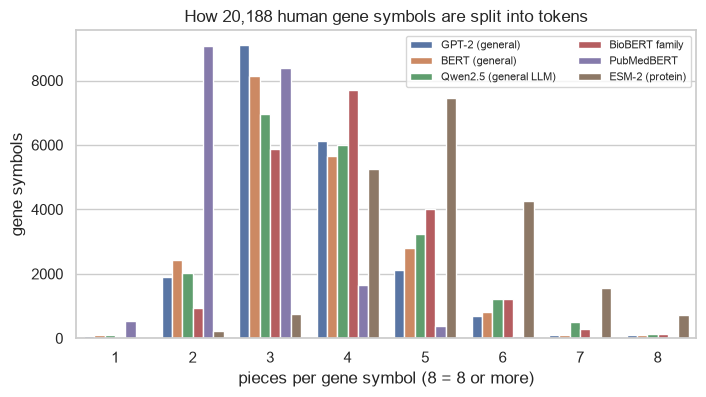

In [5]:
# How often is each gene symbol mentioned in *other* proteins' function text? A rough proxy for how well studied it is.
all_function_text = " ".join(human["function"].dropna())
words = pd.Series(re.findall(r"[A-Za-z0-9-]+", all_function_text)).value_counts()
mentions = pd.Series(genes, index=genes).map(words).fillna(0)
well_studied = mentions.nlargest(200).index

rows, n_pieces = [], {}
for name, tok in toks.items():
    n = np.array([len(pieces(tok, g)) for g in genes])
    n_pieces[name] = n
    rows.append({"tokeniser": name, "vocabulary": tok.vocab_size, "symbols kept whole": (n == 1).mean(),
                 "mean pieces per symbol": n.mean(),
                 "kept whole: 200 most-mentioned genes": np.mean([len(pieces(tok, g)) == 1 for g in well_studied])})  # fmt: skip
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
data = pd.DataFrame({k: np.clip(v, 1, 8) for k, v in n_pieces.items()}).melt(
    var_name="tokeniser", value_name="pieces"
)
sns.countplot(data=data, x="pieces", hue="tokeniser", ax=ax)
ax.set(xlabel="pieces per gene symbol (8 = 8 or more)", ylabel="gene symbols",
       title=f"How {len(genes):,} human gene symbols are split into tokens")  # fmt: skip
ax.legend(fontsize=8, ncol=2)
fig.savefig(FIGURES / "01_gene_symbol_pieces.png", dpi=150, bbox_inches="tight")
plt.show()

**General tokenisers almost never keep a gene symbol whole.** Out of 20,188 human gene symbols, GPT-2, BERT and
Qwen2.5 keep 0.3–0.5 % as one token and need 3.6–3.8 pieces on average; TP53 becomes `TP` + `53`, or even `TP` + `5` +
`3`. The pieces are reused for unrelated things (`CD` is also a compact disc; `53` is just a number).

**PubMedBERT is the exception, for well-studied genes.** Its vocabulary was built from PubMed text, so frequent gene
names got their own token: *tp53*, *brca1*, *egfr*, *cdkn2a* are single pieces. That holds for **52 %** of the 200
genes most often mentioned in other proteins' UniProt descriptions, but for only 2.7 % of all symbols. **A tokeniser
reflects what was common in its training text:** famous genes are "words", the other 19,000 are spelled out.

*(The BioBERT family kept BERT's original vocabulary, built from Wikipedia and books, so it is no better than BERT
here. ESM-2's vocabulary is 33 tokens, essentially the amino-acid letters, so it spells everything out.)*

## 3 · DNA and protein sequences

> **In plain language.** DNA is written with four letters (A, C, G, T) and proteins with twenty. Text tokenisers
> were never built for long strings without spaces. Models built for sequences use different schemes: protein
> language models such as ESM-2 use **one token per amino acid**; DNA models use single letters, fixed-length
> **k-mers** (overlapping "words" of k letters, as in DNABERT), or pieces learned from genomes (DNABERT-2).

In [6]:
rng = np.random.default_rng(SEED)
dna = "".join(rng.choice(list("ACGT"), 300))
protein = human.loc[human["gene"] == "TP53", "sequence"].item()[:300]
rows = []
for name, tok in toks.items():
    d, p = tok.tokenize(dna), tok.tokenize(protein)
    rows.append({"tokeniser": name, "DNA (300 letters) → tokens": len(d), "first DNA tokens": " · ".join(d[:6]),
                 "protein (300 letters) → tokens": len(p), "first protein tokens": " · ".join(p[:6])})  # fmt: skip
rows.append({"tokeniser": "3-mers (DNABERT-style, dsls.seq.kmers)", "DNA (300 letters) → tokens": len(list(kmers(dna, 3))),
             "first DNA tokens": " · ".join(list(kmers(dna, 3))[:6])})  # fmt: skip
pd.DataFrame(rows)

,tokeniser,DNA (300 letters) → tokens,first DNA tokens,protein (300 letters) → tokens,first protein tokens
0,GPT-2 (general),154,T · GG · CC · AAA · AT · GT,173.0,M · EEP · Q · SD · PS · VE
1,BERT (general),1,[UNK],1.0,[UNK]
2,Qwen2.5 (general LLM),155,T · GG · CC · AAA · AT · GT,159.0,M · EEP · Q · SD · PS · VE
3,BioBERT family,1,[UNK],1.0,[UNK]
4,PubMedBERT,1,[UNK],1.0,[UNK]
5,ESM-2 (protein),300,T · G · G · C · C · A,300.0,M · E · E · P · Q · S
6,"3-mers (DNABERT-style, dsls.seq.kmers)",298,TGG · GGC · GCC · CCA · CAA · AAA,NaN,NaN


In [7]:
# Does the same DNA "word" always become the same tokens? Find GATTACA in different surroundings.
for context in ("GATTACA", "CGATTACAG", "TTGATTACATT", "AGATTACAAGATTACA"):
    print(f"{context:18s} Qwen2.5 → {' · '.join(toks['Qwen2.5 (general LLM)'].tokenize(context))}")

GATTACA            Qwen2.5 → G · ATT · ACA
CGATTACAG          Qwen2.5 → CG · ATT · AC · AG
TTGATTACATT        Qwen2.5 → TT · G · ATT · AC · ATT
AGATTACAAGATTACA   Qwen2.5 → AG · ATT · ACA · AG · ATT · ACA


**Two surprises:**

1. **BERT-style tokenisers turn a 300-letter DNA or protein sequence into a single `[UNK]`** ("unknown"). WordPiece
   gives up on any "word" longer than 100 characters. The model receives one meaningless token, and nothing warns you.
2. **ESM-2 happily accepts DNA,** one token per letter, because A, C, G and T are also amino-acid letters (alanine,
   cysteine, glycine, threonine). A protein model will embed a DNA sequence as a strange protein without complaint.
   **Check the input type yourself.**

**General LLM tokenisers chop DNA into irregular chunks** (`T · GG · CC · AAA · AT · GT`, about 2 letters per token),
and the chunks depend on the neighbours: GATTACA becomes `G · ATT · ACA` on its own, `CG · ATT · AC · AG` with one
letter added on each side, and differs again elsewhere in a sequence. The same motif looks different to the model
depending on context. DNA models avoid this with single letters or **k-mers**: overlapping 3-letter words give 298
tokens for 300 letters, always the same for the same motif.

## 4 · A character-level task: counting letters

Counting the Gs in a short DNA string is trivial for a person or one line of code, but an LLM sees tokens such as
`GG` or `ATT`, not letters. Does writing the letters with spaces (so each letter becomes its own token) help?
40 random DNA strings of 12–24 letters, answered greedily by Qwen2.5-0.5B-Instruct:

In [8]:
@torch.no_grad()
def ask(question, max_new_tokens=12):
    ids = tok_llm.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True,
                                      return_tensors="pt").to(DEVICE)  # fmt: skip
    out = llm.generate(
        ids, max_new_tokens=max_new_tokens, do_sample=False, top_p=None, top_k=None, temperature=None
    )
    return tok_llm.decode(out[0, ids.shape[1] :], skip_special_tokens=True).strip()


rng = np.random.default_rng(SEED)
rows = []
for _ in range(40):
    s = "".join(rng.choice(list("ACGT"), int(rng.integers(12, 25))))
    for style, shown in (("plain", s), ("spaced letters", " ".join(s))):
        answer = ask(
            f"How many times does the letter G appear in this DNA sequence: {shown}\nAnswer with a single number only."
        )
        number = re.search(r"\d+", answer)
        rows.append({"style": style, "true": s.count("G"), "answer": int(number.group()) if number else None})
counts = pd.DataFrame(rows)
counts["correct"] = counts["answer"] == counts["true"]
counts["off by"] = (counts["answer"] - counts["true"]).abs()
display(counts.groupby("style")[["correct", "off by"]].mean().round(2))
print("Python, for comparison: 'GATTACAGG'.count('G') =", "GATTACAGG".count("G"))

,correct,off by
style,,
plain,0.08,4.05
spaced letters,0.05,5.38


Python, for comparison: 'GATTACAGG'.count('G') = 3


**Qwen2.5-0.5B can't count letters, with or without spaces:** 8 % correct on plain strings and 5 % with spaced
letters, off by 4–5 on average, roughly what guessing would give. Spacing the letters gives each its own token but
doesn't help this small model. So this test can't isolate tokenisation as the cause: the model is simply not able to
count. Larger models do better (I did not test them here), but counting characters is a known weak spot of LLMs.

The practical lesson is the one in the course's agents section: **for exact operations (counting, sequence lengths,
GC content, motif search) the LLM should call code**, such as `str.count` or the functions in
[`dsls.seq`](../../../src/dsls/seq.py), rather than "think" the answer. An agent is an LLM that knows when to do that.

## Conclusions

1. **An LLM predicts the next token from learned probabilities.** It always produces a fluent continuation; when the
   fact isn't well represented (TP53's UniProt accession), it has no confident answer but will still write one.
2. **Temperature trades reliability for variety:** greedy decoding gave a correct summary of p53; temperature 0.7
   produced fluent but wrong biology.
3. **General tokenisers shred gene symbols** (0.3–0.5 % kept whole); PubMedBERT keeps half of the most-studied genes
   whole, because its vocabulary came from biomedical text.
4. **Sequences need sequence tokenisers:** BERT-style tokenisers reduce DNA and protein to a single `[UNK]`, general
   LLMs split DNA inconsistently, and a protein model silently accepts DNA.
5. **Exact operations belong in code,** not in the language model: the 0.5B model counted letters correctly 5–8 % of
   the time.

*Models: Qwen2.5-0.5B-Instruct (Apache-2.0), GPT-2 (MIT), BERT (Apache-2.0), nlpie/distil-biobert (MIT), PubMedBERT
(MIT), ESM-2 (MIT), downloaded to the local Hugging Face cache, not committed. Data: UniProtKB/Swiss-Prot
([CC BY 4.0](https://www.uniprot.org/help/license)). Runtime: about 3 minutes on an Apple-silicon laptop.*